# Lab 6: Localization (odometry)

# Adhambek Yashnarbekov — 240062

The robot drives my digits 62 with motors and timers, like in Lab 1. At the same time a second task reads the encoders, counts the odometry with the formulas from the board and writes `x,y,time` to a file in a loop with a 5 ms timer. The simulator and the real robot run the same blocks. Only these things are different: r and B (0.028 m and 0.154 m in the simulator, 0.0375 m and 0.194 m on the real robot), the turn timers (550 ms on the real robot instead of 1000 ms, because its motors are faster), the file name, and the marker, which is only in the simulator.

Upload `odometry_data_sim.txt` and `odometry_data_real.txt` in the next cell.

In [14]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select BOTH txt files

Saving odometry_data_real.txt to odometry_data_real (2).txt
Saving odometry_data_sim.txt to odometry_data_sim (3).txt


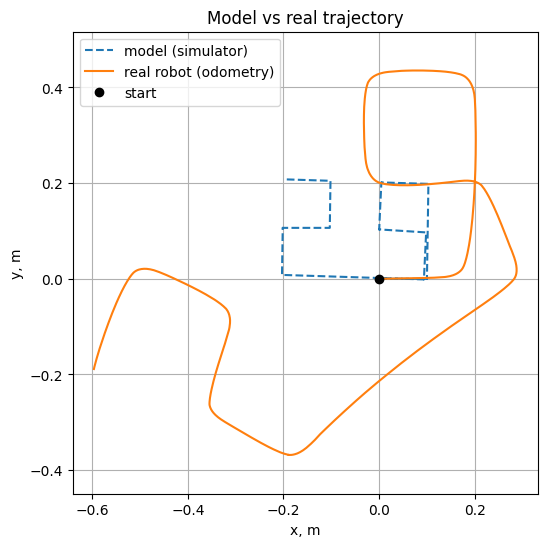

In [15]:
x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)

# 1. Trajectories on one plot
plt.figure(figsize=(6, 6))
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Model vs real trajectory')
plt.show()

In the simulator the robot drew the 62. In the plot it is turned, because x is the direction the robot faced at the start. The real 62 is about twice as big, and its "2" is turned to the left, because on the real robot the right corners are smaller than 90°.

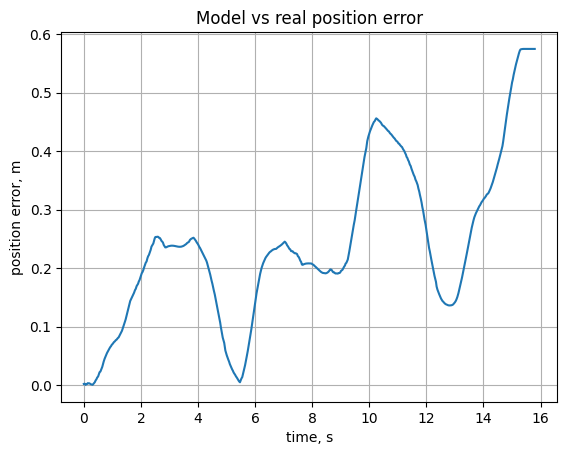

Final odometry error (sim vs real): 0.6 m
Max error: 0.6 m


In [16]:
# 2. Error over time (simulator resampled onto the real-robot timestamps)
t_s, t_r = t_s - t_s[0], t_r - t_r[0]
xs_i = np.interp(t_r, t_s, x_s)
ys_i = np.interp(t_r, t_s, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)

plt.plot(t_r / 1000, err)
plt.xlabel('time, s'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('Model vs real position error')
plt.show()

print(f'Final odometry error (sim vs real): {err[-1]:.1f} m')
print(f'Max error: {err.max():.1f} m')

## Measured end point

Before the run I put a mark A under the centre of the robot and a mark B 1 m behind it, on the line of the start direction. After the run I put a mark C under the centre of the robot. C is 20 cm to the right of this line, A–C = 50 cm and B–C = 60 cm, so along the line C is about 45 cm behind A (46 cm counted from A, 43 cm counted from B). x is the start direction and y is to the left, so the real end point is x = -0.45 m, y = -0.20 m.

In [17]:
x_tape = -0.45                        # measured with a tape, m
y_tape = -0.20

print(f'Odometry (last line): x = {x_r[-1]:.2f} m, y = {y_r[-1]:.2f} m')
print(f'Tape:                 x = {x_tape:.2f} m, y = {y_tape:.2f} m')
print(f'Difference: {np.hypot(x_r[-1] - x_tape, y_r[-1] - y_tape):.2f} m')

Odometry (last line): x = -0.60 m, y = -0.19 m
Tape:                 x = -0.45 m, y = -0.20 m
Difference: 0.15 m


## Conclusions

The real trajectory diverges from the model from the first piece: with the same forward timers the real robot drives about twice as far (2.9 m against 1.4 m in the simulator), so its 62 is about twice as big. The left corners came out about 90° (76–95°), but the right corners only 67–76°, so after every right turn the robot faces more to the left than in the model. This is the "unequal wheels / motors" error from the lecture: the real motors are faster than the simulated ones, and the wheels do not turn the robot the same way to the left and to the right. Because heading error dominates, the 15–25° missing at the four right corners add up to about 60° by the end, and together with the bigger size this gives a final error of 0.6 m, which is also the max error. The odometry itself is wrong too: the tape shows the real end point 0.15 m away from the last odometry point, most likely because of wheel slip in the turns in place. The robot does not know it is wrong, because it only counts wheel rotations and slip is invisible to the encoders.